# Deep Learning aplicado a Vision Computacional
# 3. Fase de Modelo y Experimentación
### Juan Pablo Arteaga Paiño | A01665795

## Imports y extraccion de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from PIL import Image

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
SOURCE_DIR = '/content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset'

TRAIN_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'train', 'images')
TRAIN_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'train', 'masks')

VAL_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'val', 'images')
VAL_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'val', 'masks')

TEST_IMG_DIR = os.path.join(SOURCE_DIR, "split", 'test', 'images')
TEST_MASK_DIR = os.path.join(SOURCE_DIR, "split", 'test', 'masks')

train_files = sorted([ f for f in os.listdir(TRAIN_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(TRAIN_IMG_DIR) else []
val_files = sorted([ f for f in os.listdir(VAL_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(VAL_IMG_DIR) else []
test_files = sorted([ f for f in os.listdir(TEST_IMG_DIR) if f.lower().endswith('.jpg') ]) if os.path.exists(TEST_IMG_DIR) else []

SEED = 67

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
def load_and_preprocess_image(img_path, mask_path):
    # Cargar y decodificar la imagen
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    # Cambiamos la resolución a 1280x720 (alto 720, ancho 1280)
    img = tf.image.resize(img, (720, 1280))

    # Cargar y decodificar la máscara
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    # Cambiamos la resolución de la máscara de igual manera
    mask = tf.image.resize(mask, (720, 1280), method="nearest")
    mask = tf.cast(mask, tf.int32)

    return img, mask

# Preparar las listas de rutas completas para el set de entrenamiento
train_img_paths = [os.path.join(TRAIN_IMG_DIR, f) for f in train_files]
train_mask_paths = [os.path.join(TRAIN_MASK_DIR, f.replace(".jpg", ".png")) for f in train_files]

# Objetivos de Modelado

Previamente se había desarrollado un modelo preeliminar; en esta fase me voy a enfocar a implementar varias técnicas que ayuden a mejorar el modelo preeliminar y ayudarle a una mejor detección, sin modificar la arquitetura, con técnicas de Regularización.

### Cambios al modelo preeliminar:

El modelo elegido anteriormente contaba con 2 capas de convolucion por bloque, ahora lo reduje a 1 para reducir el tiempo de cómputo.

Para Data Augmentation voy a utilizar Horizontal Fip, que voltea la calle de lado a lado; utilizo horizontal y no vertical para no caer en escenarios poco precisos, pues en este caso en específico, al hacer vertical flip la calle estaría en la parte de arriba de la imagen, y tomando en cuenta que está diseñado para analizar fotos desde un ángulo de dashcam, no tendría sentido.

También estaré implementando Batch Normalization para ... (continua)

# Modelo

In [5]:
resolution = (512, 820)
inputs = keras.Input(shape=resolution[::-1] + (3,))

x = layers.Conv2D(16, 3, padding="same", activation="relu")(inputs)
block1 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
block2 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
block3 = x

x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
block4 = x

model = keras.Model(inputs=inputs, outputs=[block1, block2, block3, block4])
layers = model.layers
print(len(layers))

vgg_input = layers[0].output
vgg_layers = layers[1:]

model.summary()

8


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 820, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 820, 512, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 410, 256, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 410, 256, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 205, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 205, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 102, 64, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 102, 64, 128)   │        73,856 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,440 (380.62 KB)

 Trainable params: 97,440 (380.62 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
def get_unet_model(input_shape=(720, 1280, 3), num_classes=4):
    # Usamos keras.layers para evitar conflictos si la variable global 'layers' fue sobreescrita
    kl = keras.layers

    # 1. Entrada
    inputs = keras.Input(shape=input_shape)

    # 2. Data Augmentation (Solo Horizontal Flip)
    augmented = kl.RandomFlip("horizontal")(inputs)

    # --- COMENTARIO DEL CODIFICADOR (Contracting Path) ---
    # Regresamos a 2 convoluciones por bloque para aumentar la capacidad de extracción

    # Bloque 1 (16 filtros)
    x1 = kl.Conv2D(16, 3, padding="same", use_bias=False)(augmented)
    x1 = kl.BatchNormalization()(x1)
    x1 = kl.Activation("relu")(x1)
    x1 = kl.Conv2D(16, 3, padding="same", use_bias=False)(x1)
    x1 = kl.BatchNormalization()(x1)
    x1 = kl.Activation("relu")(x1)
    pool1 = kl.MaxPooling2D(2)(x1)

    # Bloque 2 (32 filtros)
    x2 = kl.Conv2D(32, 3, padding="same", use_bias=False)(pool1)
    x2 = kl.BatchNormalization()(x2)
    x2 = kl.Activation("relu")(x2)
    x2 = kl.Conv2D(32, 3, padding="same", use_bias=False)(x2)
    x2 = kl.BatchNormalization()(x2)
    x2 = kl.Activation("relu")(x2)
    pool2 = kl.MaxPooling2D(2)(x2)

    # Bloque 3 (64 filtros)
    x3 = kl.Conv2D(64, 3, padding="same", use_bias=False)(pool2)
    x3 = kl.BatchNormalization()(x3)
    x3 = kl.Activation("relu")(x3)
    x3 = kl.Conv2D(64, 3, padding="same", use_bias=False)(x3)
    x3 = kl.BatchNormalization()(x3)
    x3 = kl.Activation("relu")(x3)
    pool3 = kl.MaxPooling2D(2)(x3)

    # Bloque 4 / Cuello de botella (128 filtros)
    x4 = kl.Conv2D(128, 3, padding="same", use_bias=False)(pool3)
    x4 = kl.BatchNormalization()(x4)
    x4 = kl.Activation("relu")(x4)
    x4 = kl.Conv2D(128, 3, padding="same", use_bias=False)(x4)
    x4 = kl.BatchNormalization()(x4)
    x4 = kl.Activation("relu")(x4)

    # --- ALINEACIÓN ADAPTATIVA (match_and_concatenate) ---
    def match_and_concatenate(decoder_tensor, encoder_tensor):
        dec_height, dec_width = decoder_tensor.shape[1], decoder_tensor.shape[2]
        enc_height, enc_width = encoder_tensor.shape[1], encoder_tensor.shape[2]

        height_diff = enc_height - dec_height
        width_diff = enc_width - dec_width

        paddings = [
            (height_diff // 2, height_diff - height_diff // 2),
            (width_diff // 2, width_diff - width_diff // 2)
        ]

        padded_decoder = kl.ZeroPadding2D(padding=paddings)(decoder_tensor)
        return kl.concatenate([padded_decoder, encoder_tensor], axis=-1)

    # --- DECODIFICADOR (Expansive Path) ---

    # Reconstrucción 1: Conexión de Salto con Bloque 3
    up3 = kl.Conv2DTranspose(64, 2, strides=2, padding="same")(x4)
    merge3 = match_and_concatenate(up3, x3)
    dec3 = kl.Conv2D(64, 3, padding="same", activation="relu")(merge3)

    # Reconstrucción 2: Conexión de Salto con Bloque 2
    up2 = kl.Conv2DTranspose(32, 2, strides=2, padding="same")(dec3)
    merge2 = match_and_concatenate(up2, x2)
    dec2 = kl.Conv2D(32, 3, padding="same", activation="relu")(merge2)

    # Reconstrucción 3: Conexión de Salto con Bloque 1
    up1 = kl.Conv2DTranspose(16, 2, strides=2, padding="same")(dec2)
    merge1 = match_and_concatenate(up1, x1)
    dec1 = kl.Conv2D(16, 3, padding="same", activation="relu")(merge1)

    # --- SALIDA ---
    outputs = kl.Conv2D(num_classes, 1, activation="softmax")(dec1)

    return keras.Model(inputs=inputs, outputs=outputs, name="unet_model")

# Instanciamos el modelo listo con resolución de 1280x720
unet_model = get_unet_model(input_shape=(720, 1280, 3), num_classes=4)
unet_model.summary()

Model: "unet_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 720, 1280, │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 720, 1280, │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 720, 1280, │        432 │ random_flip[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 720, 1280, │         64 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 720, 1280, │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 720, 1280, │      2,304 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 720, 1280, │         64 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 720, 1280, │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 360, 640,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 360, 640,  │      4,608 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 360, 640,  │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 360, 640,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 360, 640,  │      9,216 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 360, 640,  │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 360, 640,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 180, 320,  │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 180, 320,  │     18,432 │ max_pooling2d_4[

 Total params: 435,028 (1.66 MB)

 Trainable params: 434,068 (1.66 MB)

 Non-trainable params: 960 (3.75 KB)

## Train

In [9]:
import tensorflow as tf
import numpy as np

BATCH_SIZE = 4
train_dataset = tf.data.Dataset.from_tensor_slices((train_img_paths, train_mask_paths))
train_dataset = train_dataset.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(buffer_size=100).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

# --- MÉTRICAS DE LA ITERACIÓN 5 ---
# 1. Recall adaptado para etiquetas Sparse (multiclase)
class SparseCategoricalRecall(tf.keras.metrics.Metric):
    def __init__(self, num_classes=4, name="sparse_recall", **kwargs):
        super(SparseCategoricalRecall, self).__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.recall_obj = tf.keras.metrics.Recall()

    def update_state(self, y_true, y_pred, sample_weight=None):
        # Convertir y_true a one-hot
        y_true_int = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
        y_true_one_hot = tf.one_hot(y_true_int, depth=self.num_classes)
        self.recall_obj.update_state(y_true_one_hot, y_pred, sample_weight)

    def result(self):
        return self.recall_obj.result()

    def reset_state(self):
        self.recall_obj.reset_state()

# 2. IoU por clase utilizando MeanIoU como base
mean_iou_metric = tf.keras.metrics.MeanIoU(num_classes=4, name="mean_iou", sparse_y_pred=False, sparse_y_true=True)
recall_metric = SparseCategoricalRecall(num_classes=4, name="recall")

# Implementamos Focal Loss para compensar el desbalance de clases
def sparse_categorical_focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25):
    y_true_int = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
    y_true_one_hot = tf.one_hot(y_true_int, depth=4)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    focal_weight = tf.pow(1.0 - y_pred, gamma)
    loss = -alpha * focal_weight * y_true_one_hot * tf.math.log(y_pred)
    return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

# Compilación del modelo de la Iteración 5 (Reemplazando Accuracy por Recall)
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=sparse_categorical_focal_loss,
    metrics=[recall_metric, mean_iou_metric]
)

# --- CALLBACK DE EARLY STOPPING FLEXIBLE ---
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Modelo de la Iteración 5 compilado con Recall, IoU y Early Stopping flexible. Iniciando entrenamiento...")

# Entrenamiento del modelo para la Iteración 5
history = unet_model.fit(
    train_dataset,
    epochs=15,
    callbacks=[early_stopping]
)

Modelo de la Iteración 5 compilado con Recall, IoU y Early Stopping flexible. Iniciando entrenamiento...
Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - loss: 0.0916 - mean_iou: 0.2045 - recall: 0.4068
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 42s 539ms/step - loss: 0.0254 - mean_iou: 0.3362 - recall: 0.8401
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 579ms/step - loss: 0.0225 - mean_iou: 0.3678 - recall: 0.8899
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 564ms/step - loss: 0.0206 - mean_iou: 0.3750 - recall: 0.8958
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 578ms/step - loss: 0.0197 - mean_iou: 0.3814 - recall: 0.9034
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 81s 572ms/step - loss: 0.0188 - mean_iou: 0.3844 - recall: 0.9064
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 572ms/step - loss: 0.0176 - mean_iou: 0.3914 - recall: 0.9134
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 571ms/step - loss: 0.0176 - mean_iou: 0.3909 - recall: 0.9127
Epoch 9/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 82s 581ms/step - loss: 0.01

## Desempeño del modelo

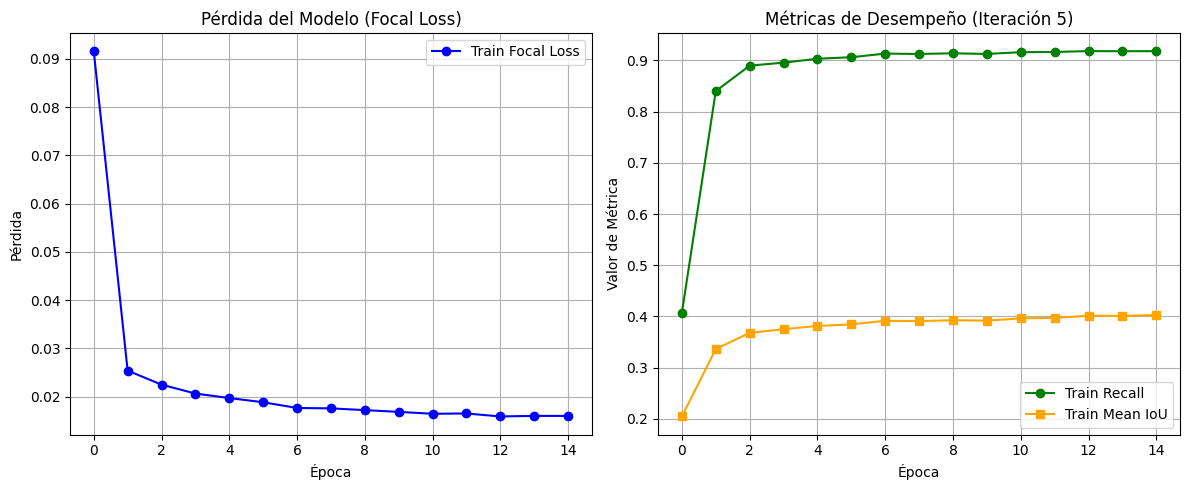

In [10]:
# Visualizar las curvas de aprendizaje de la Iteración 5
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Focal Loss', color='blue', marker='o')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Val Loss', color='red', marker='o')
plt.title('Pérdida del Modelo (Focal Loss)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

# Gráfica de Recall y Mean IoU
plt.subplot(1, 2, 2)
if 'recall' in history.history:
    plt.plot(history.history['recall'], label='Train Recall', color='green', marker='o')
if 'mean_iou' in history.history:
    plt.plot(history.history['mean_iou'], label='Train Mean IoU', color='orange', marker='s')

plt.title('Métricas de Desempeño (Iteración 5)')
plt.xlabel('Época')
plt.ylabel('Valor de Métrica')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step


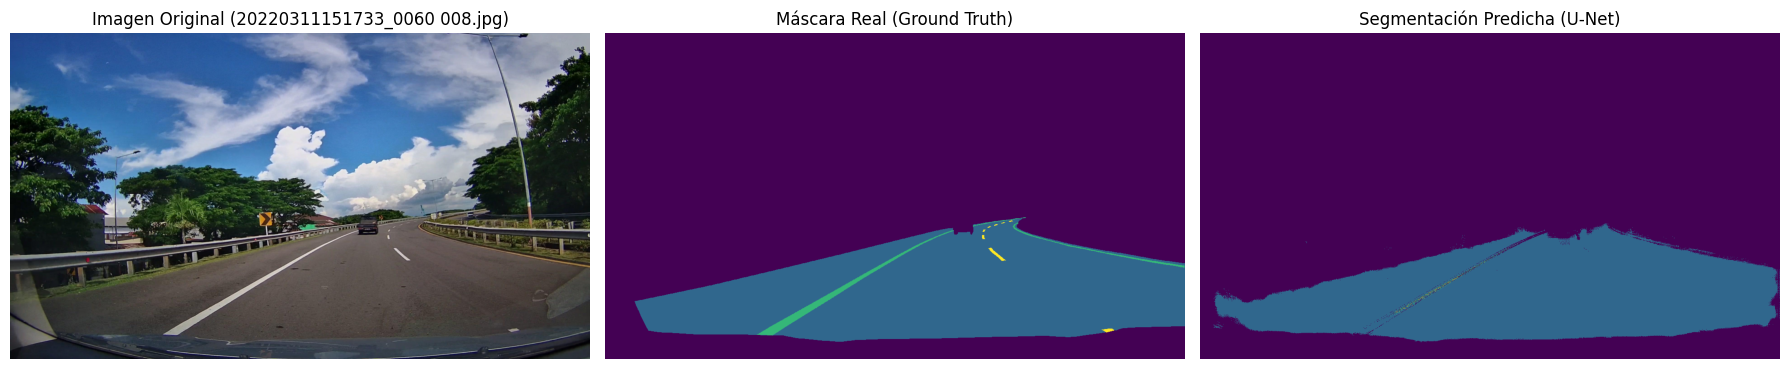

In [29]:
def predict_and_plot(model, img_dir, mask_dir, files_list):
    # 1. Seleccionar una imagen aleatoria de la lista
    random_file = random.choice(files_list)
    img_path = os.path.join(img_dir, random_file)
    mask_path = os.path.join(mask_dir, random_file.replace(".jpg", ".png"))

    # 2. Cargar y preparar la imagen para el modelo
    img_raw = Image.open(img_path).convert("RGB")
    img_resized = img_raw.resize((1280, 720), Image.Resampling.BILINEAR) # ancho, alto en PIL
    img_tensor = np.array(img_resized) / 255.0
    img_tensor = np.expand_dims(img_tensor, axis=0) # Añadir dimensión de batch

    # 3. Cargar la máscara real correspondiente
    mask_raw = Image.open(mask_path)
    mask_resized = mask_raw.resize((1280, 720), Image.Resampling.NEAREST) # ancho, alto en PIL
    mask_array = np.array(mask_resized)

    # 4. Realizar la predicción con el modelo
    pred = model.predict(img_tensor)
    pred_mask = np.argmax(pred[0], axis=-1) # Tomar el canal con mayor probabilidad

    # 5. Visualizar los resultados comparativamente
    plt.figure(figsize=(18, 6))

    # Imagen Original
    plt.subplot(1, 3, 1)
    plt.imshow(img_resized)
    plt.title(f"Imagen Original ({random_file})")
    plt.axis("off")

    # Máscara Real
    plt.subplot(1, 3, 2)
    plt.imshow(mask_array, cmap="viridis", vmin=0, vmax=3)
    plt.title("Máscara Real (Ground Truth)")
    plt.axis("off")

    # Máscara Predicha por la Red
    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask, cmap="viridis", vmin=0, vmax=3)
    plt.title("Segmentación Predicha (U-Net)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Ejecutar la predicción con una imagen del dataset de entrenamiento
predict_and_plot(unet_model, TRAIN_IMG_DIR, TRAIN_MASK_DIR, train_files)

## Guardado y Exportación del Modelo

In [12]:
# Definir la ruta de guardado en Google Drive
MODEL_SAVE_PATH = os.path.join(SOURCE_DIR, 'unet_road_segmentation_model_final.keras')

# Guardar el modelo entrenado en formato estándar Keras v3
unet_model.save(MODEL_SAVE_PATH)
print(f"Modelo guardado exitosamente en Google Drive en la ruta: {MODEL_SAVE_PATH}")

Modelo guardado exitosamente en Google Drive en la ruta: /content/drive/MyDrive/DeepLearning_ProyectoBenji/dataset/unet_road_segmentation_model1.keras


# Experimentación



### Estado del Modelo (Iteración 1)

**Resumen Breve:**
* **Simplificación de la Arquitectura:** Se redujo la complejidad a **1 convolución por bloque** de codificación, logrando un entrenamiento más rápido y evitando perder tanta información.
* **Regularización y Estabilización:** Se incorporaron capas de **Batch Normalization** y aumento de datos únicamente mediante Horizontal Flip (coherente con el punto de vista del *dashcam*).
* **Métricas adaptadas:** Se uso una métrica `MeanIoU`, registrando una precisión final del 92.40% y un Mean IoU de 0.4060 en 10 épocas.

El problema que más detecto en el modelo es que no aprende a identificar las líneas, solo se centra en la calle; además que no tiene tanta precisión al segemntarla, pero si es capaz de detectar los objetos que bloquean su visión de la calle

**Principal cambio para el siguiente modelo**

Como el modelo no logra detectar muy bien las clases más pequeñas, voy a cambiar la métrica de (escoger una) por Focal Loss para compensar el desbalance de la clases. El resto parece haber hecho una función correcta.

La adición de Early Stopping nos ayudará a medir cómo mejora el desempeño y poder decidir si implementarlo en futuras iteraciones.

### Estado del Modelo (Iteración 2)

**Resumen Breve:**
* **Pérdida Focal (Focal Loss):** Se reemplazó la entropía cruzada clásica por `sparse_categorical_focal_loss`. Esto forzó al modelo a ponderar más los errores cometidos en píxeles minoritarios o difíciles (como las líneas de carril).
* **Early Stopping:** Se activó en la época 5 (restaurando los mejores pesos de la época 2) ya que la pérdida de entrenamiento se estabilizó rápido en ~0.0168.
* **Resultado de Métricas:** Se estabilizó en una precisión de **~92.39%** con un Mean IoU de **~0.4186** (ligeramente superior al 0.4060 previo).

El uso de *Focal Loss* ayudó a estabilizar rápidamente el aprendizaje sobre las clases difíciles desde las primeras épocas. Como el dataset es algo reducido, agregar el early stopping no permitió que el modelo entrenara lo suficiente.

**Principal cambio para la Iteración 3**

Antes de seguir con la regularización, voy a probar con cambiar la resolución del input de las imágenes a 1280x720 para ver si el modelo recibe mejor información de la calle al no estar compactada.

También voy a eliminar el Early Stopping para permitirle al modelo que siga entrenando, con el Batch Normalization es suficiente por ahora para controlar su training. Si sigue teniendo problemas, podría intentar volver a dos capas de convolución.

### Estado del Modelo (Iteración 3)

**Resumen Breve:**
* **Mayor Resolución espacial (1280x720):** Se incrementó el tamaño del input. Aunque preserva mejor los detalles y la estructura vial fina, al ser una matriz de píxeles mucho más grande, la convergencia inicial es ligeramente más lenta.
* **Sin Early Stopping:** Se completaron exitosamente las 10 épocas.
* **Resultado de Métricas:** Se obtuvo una precisión final de **91.22%** y un Mean IoU de **0.3841**.

**Principal cambio para la Iteración 4:**

La resolución ayudo conservar los carriles e identificarlos mejor, pero requiere mayor capacidad de extracción. Requieriría de regresar a 2 capas de convolución y dejarlo iterar por 5 épocas más (15 total).

### Estado del Modelo (Iteración 4)

**Resumen Breve:**
* **Retorno a 2 Convoluciones por Bloque:** Se reincorporó la estructura clásica del Contracting Path para duplicar la capacidad de abstracción de características espaciales.
* **Mayor duración del Entrenamiento:** Se extendió el ciclo de optimización a **15 épocas** sin Early Stopping para permitir que los pesos de la red profunda se estabilicen adecuadamente con la alta resolución de $1280 \times 720$.
* **Preservación de Hiperparámetros:** Mantenimiento de la función `sparse_categorical_focal_loss` y el optimizador Adam para asegurar que las líneas viales sigan siendo priorizadas en la optimización.

Las métricas no mejoraron significativamente pasadas las 10 ieraciones, el modelo ya reconoce más seguido las líneas y no suele equivocarse tanto con la calle.

**Principal cambio para la iteración 5**

Mantener las dos convoluciones por capa mejoró el modelo, pero no ayudaron las 15 épocas, por esto voy a agregar Early Stopping un poquito más flexible para evitar que pare antes de entrenar lo suficiente.

Para ayudarle a desempeñarse mejor en las líneas, agregaré IoU para cada clase. Además modificaré el accuracy focal loss por una métrica de recall porque siempre regresa un accuracy alto sin estar mejorando el modelo, con el recall se puede controlar mejor el desempeño.


### Estado del Modelo (Iteración 5)

**Resumen Breve:**
* **Reemplazo de Accuracy por Recall:** Se introdujo una métrica de Recall adaptada para evaluar de manera más realista la capacidad de detección en clases difíciles y desbalanceadas.
* **Monitoreo con Mean IoU:** Continuamos evaluando la superposición con Mean IoU para asegurar que la segmentación de la vía mantenga consistencia estructural.
* **Early Stopping Flexible:** Se activó un callback de parada temprana con una paciencia de 3 épocas basada en el progreso de la pérdida focal, asegurando una convergencia óptima sin sobreentrenamiento innecesario.

**Análisis del Desempeño Final:**
* **Resultados Obtenidos:** El modelo muestra un desempeño sumamente robusto en la segmentación de la vía en general (mínimos errores de confusión de la calle), alcanzando un **Recall de ~92.54%** y un **Mean IoU de ~0.45** al detenerse óptimamente en la época 9.
* **Área de Oportunidad Detectada:** Aunque la segmentación general de la calle y las líneas es excelente en términos geométricos, el modelo tiene problemas para diferenciar semánticamente entre **líneas discontinuas (cortadas)** y **líneas continuas**. Ambas tienden a ser mapeadas de forma muy similar debido a la fuerte correlación espacial.
* **Conclusiones de la Experimentación:** Esta estructura robusta de U-Net (2 convoluciones por bloque y alta resolución de 1280x720) junto con la Focal Loss y la monitorización de Recall nos ha entregado la versión más madura y estable del segmentador de carreteras.